In [1]:
import sys, os, datetime, importlib

import pandas as pd
import numpy as np
import scipy
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F

import torchvision
read = torchvision.datasets.CIFAR10(root='ds_CIFAR10', train=True, download=False)
read = torch.as_tensor(read.data[:200]).clone().swapaxes(-1,-3)

In [1026]:
train = (read[:50,0,None,:16,:16].flatten(2).to(torch.float32)/255).to('cuda')

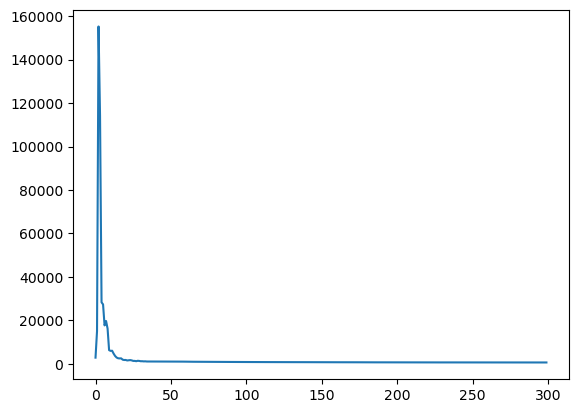

tensor([619.1176], device='cuda:0')


In [2731]:
import nn_tf; importlib.reload(nn_tf)
import nn_reg; importlib.reload(nn_reg)
import nn_util; importlib.reload(nn_util)

def calc_loss(x, y):
    return (x - y).pow(2).sum(dim=-1).mean()
    #gmae = (x - y).abs().sum(dim=-1).pow(2).sum().pow(0.5)
    #return gmae

#train = (read[:50,0,None,:16,:16].flatten(2).to(torch.float32)/255).to('cuda')
model = nn_tf.r1PA_Transformer(h=32, dim=train.shape[-1], hdim=32, c=1, layers=12, activation='sigmoid').to(torch.float32).to('cuda')
wrapper = nn_reg.ScoreMatchingWrapper(model, calc_loss, sigma0=0.001, sigma1=1)

steps = 300
loss_hist = []
#opt = torch.optim.SGD(model.parameters(), lr=0.02, momentum=0.9, weight_decay=0.3, fused=True)
#opt = torch.optim.SGD(model.parameters(), lr=0.007, momentum=0.8, weight_decay=0.3, fused=True)
opt = torch.optim.AdamW(model.parameters(), lr=0.007, weight_decay=0.1, fused=True)
#opt = torch.optim.SGD(model.parameters(), lr=0.02, momentum=0.8, weight_decay=0.3, fused=True)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
#reg = nn_reg.Sensitizer(model.parameters(), beta=1e5, sigma0=1)
def train_step():
    opt.zero_grad()
    #result = model(feed)
    #loss = calc_loss(result, train)

    # 1. diffusionblock training
    loss = wrapper.train(train)
    # 2. sequential noised input MSE recovery training
    #feed = train + torch.randn_like(train)*(0.5 + 0.5*(1 + np.cos(torch.pi * i/steps))**2)
    #calc_loss(model(feed), train).backward()
    
    #with torch.autograd.set_detect_anomaly(True):
    #loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 0.1)
    #reg.step()
    opt.step()
    sched.step()
    
    loss_hist.append(loss.detach().item())
    return loss

for i in range(steps):
    loss = train_step()

plt.plot(loss_hist); plt.show()
print(loss)

In [2664]:
#print([model.net[i].beta.detach().item() for i in range(len(model.net))])
#print([model.net[i].alpha.detach().item() for i in range(len(model.net))])
#for param in model.net[0].parameters():
#    print(param)

(tensor(0.0026, device='cuda:0'), tensor(0.0351, device='cuda:0'))

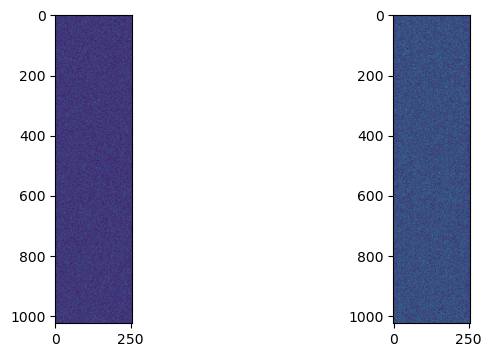

In [2732]:
plt.figure(figsize=(8,4));
plt.subplot(1,2,1); plt.imshow(model.net[0].P_q.weight.detach().cpu().abs())#; plt.colorbar(shrink=0.5)
plt.subplot(1,2,2); plt.imshow(model.net[-1].P_q.weight.detach().cpu().abs())#; plt.colorbar(shrink=0.5)

In [2705]:
test = train[:10].clone()
test += torch.randn_like(test)*0.5

result variance: 0.009038994088768959 test variance: 0.03512946143746376
CSIM input: 0.041861001402139664 inference: 0.029586557298898697


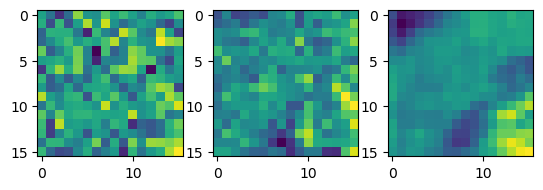

CSIM input: 0.07420794665813446 inference: 0.09037094563245773


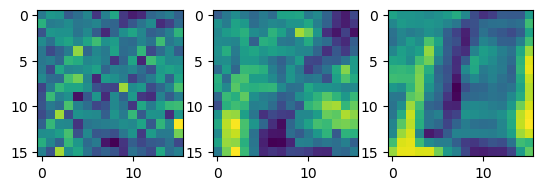

CSIM input: 0.03182035684585571 inference: 0.11266396939754486


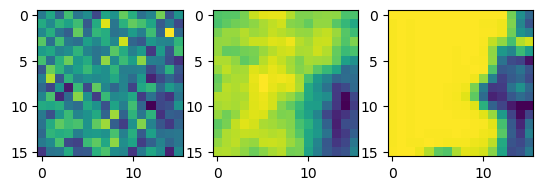

CSIM input: 0.027723729610443115 inference: 0.1740638017654419


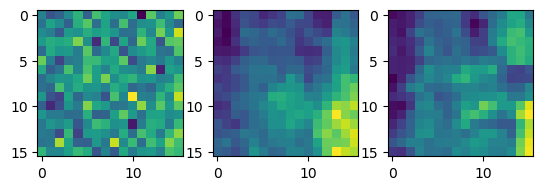

CSIM input: 0.050036586821079254 inference: 0.022306539118289948


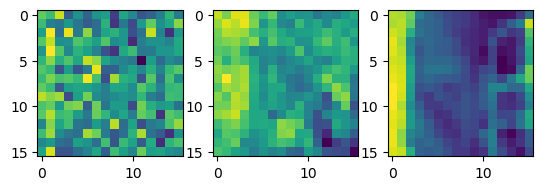

In [2737]:
import util_metrics; importlib.reload(util_metrics)

result = test.clone()
for i in range(1):
    result = model(result)
    #result = wrapper(result)

view_shape = (10, 1, 16, 16)
result = (result.view(view_shape).detach())
print('result variance:', result.detach().var(dim=-1).sum(dim=1).mean().item(), 'test variance:', train.var(dim=-1).sum(dim=1).mean().item())
test_v = test.view(view_shape)
truth_v = read[:view_shape[0],0,None,:16,:16]
#plt.imshow(result[0]); plt.show()
def show(x): plt.imshow(x.detach().cpu().moveaxis(0,-1))
for i in range(len(result)-5):
    plt.subplot(1,3,1); show(test_v[i])
    plt.subplot(1,3,2); show(result[i])
    plt.subplot(1,3,3); show(truth_v[i])
    tmp1 = torch.stack([truth_v[i], test_v[i].detach().cpu()], dim=0).permute(0,2,3,1)
    tmp1 = util_metrics.copula_sim(tmp1, 4).mean().item()
    tmp2 = torch.stack([truth_v[i], result[i].detach().cpu()], dim=0).permute(0,2,3,1)
    tmp2 = util_metrics.copula_sim(tmp2, 4).mean().item()
    print('CSIM', 'input:', tmp1, 'inference:', tmp2)
    #plt.subplot(1,4,4); plt.imshow(result[i] - test_v[i])
    plt.show()
